<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 1 · Sesión 4: Gobierno del riesgo, de datos y de modelos; tendencias y caso integrador</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: controles de calidad, PSI/AUC/calibración, razones de decisión, champion–challenger y memo para el comité</div>
</div>

## Objetivos de la sesión (2 horas)

1. Entender el **gobierno del riesgo**: comités, líneas de defensa y articulación entre riesgos, negocio, finanzas, cobranzas, auditoría y cumplimiento.
2. Aplicar **gobierno de datos**: controles de calidad de información antes de modelar o reportar.
3. Aplicar **gobierno de modelos**: monitoreo de estabilidad (PSI), deterioro del desempeño, calibración, explicabilidad y supervisión humana.
4. Probar cambios de política con **champion–challenger**.
5. Resolver la **actividad integradora**: diagnosticar el portafolio y formular recomendaciones para un comité de riesgos.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 15 min | Calidad de datos: controles automáticos |
| 2 | 25 min | Monitoreo de modelos: PSI, AUC, calibración |
| 3 | 15 min | Explicabilidad y supervisión humana |
| 4 | 15 min | Champion–challenger |
| 5 | 40 min | Actividad integradora: diagnóstico para el comité |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
p = pd.read_csv(DATA / "cartera_panel_mensual.csv.gz")
print(app.shape, p.shape)

(60060, 29) (286560, 17)


## 1. Gobierno de datos: controles de calidad
Un modelo o un reporte de comité es tan bueno como los datos que lo alimentan. Los controles mínimos se automatizan y se ejecutan **antes** de cada uso:

| Dimensión | Control |
|---|---|
| Unicidad | Llaves duplicadas |
| Completitud | % de faltantes por variable |
| Validez | Rangos y dominios (edad, montos, códigos) |
| Consistencia | Reglas cruzadas (p. ej., cuota ≤ monto; pensionista con antigüedad laboral) |
| Oportunidad | Fecha de corte y rezago de la fuente |

In [2]:
def controles_calidad(df):
    r = []
    r.append(("Unicidad", "Filas duplicadas", int(df.duplicated().sum())))
    r.append(("Unicidad", "SK_ID_CURR duplicados", int(df.SK_ID_CURR.duplicated().sum())))
    falt = df.isna().mean()
    for c in falt[falt > 0].index:
        r.append(("Completitud", f"% faltantes {c}", round(falt[c] * 100, 1)))
    edad = -df.DAYS_BIRTH / 365.25
    r.append(("Validez", "Edad fuera de [18, 75]", int(((edad < 18) | (edad > 75)).sum())))
    r.append(("Validez", "Montos no positivos", int((df[["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]] <= 0).any(axis=1).sum())))
    r.append(("Consistencia", "Cuota > monto del crédito", int((df.AMT_ANNUITY > df.AMT_CREDIT).sum())))
    r.append(("Consistencia", "DAYS_EMPLOYED = 365243 (código especial)", int((df.DAYS_EMPLOYED == 365243).sum())))
    return pd.DataFrame(r, columns=["dimensión", "control", "resultado"]).astype({"resultado": str})
controles_calidad(app)

,dimensión,control,resultado
0,Unicidad,Filas duplicadas,60.0
1,Unicidad,SK_ID_CURR duplicados,60.0
2,Completitud,% faltantes AMT_GOODS_PRICE,10.1
3,Completitud,% faltantes OCCUPATION_TYPE,28.6
4,Completitud,% faltantes EXT_SOURCE_1,56.1
5,Completitud,% faltantes EXT_SOURCE_2,0.2
6,Completitud,% faltantes EXT_SOURCE_3,19.9
7,Validez,"Edad fuera de [18, 75]",0.0
8,Validez,Montos no positivos,0.0
9,Consistencia,Cuota > monto del crédito,0.0


**Lectura:** los 60 duplicados, el 56 % de faltantes en `EXT_SOURCE_1` y el código especial 365243 deben **documentarse y tratarse** antes del modelamiento (Módulo 8). Un control que falla debe tener dueño, umbral y acción.

## 2. Gobierno de modelos: monitoreo
Entrenamos un score con las solicitudes de 2022 y lo monitoreamos en 2023-2025, como haría un equipo de validación.

- **PSI (Population Stability Index):** $PSI = \sum_i (a_i - e_i)\ln(a_i / e_i)$, con $e_i$ la distribución de desarrollo y $a_i$ la actual. Umbrales usuales: < 0,10 estable; 0,10-0,25 vigilar; > 0,25 cambio relevante.
- **Discriminación:** AUC/Gini por período.
- **Calibración:** PD media predicha vs. tasa observada.

In [3]:
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
feats = ["EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "AMT_REQ_CREDIT_BUREAU_YEAR", "REGION_RATING_CLIENT"]
X = app[feats].fillna(app[feats].median())
app["anio"] = app.FECHA_SOLICITUD.str[:4]
dev = app.anio == "2022"
mod = LogisticRegression(max_iter=2000).fit(X[dev], app.TARGET[dev])
app["pd"] = mod.predict_proba(X)[:, 1]
bins = np.quantile(app.loc[dev, "pd"], np.linspace(0, 1, 11)); bins[0], bins[-1] = 0, 1
def psi(e, a, bins):
    pe = np.histogram(e, bins)[0] / len(e); pa = np.histogram(a, bins)[0] / len(a)
    pe, pa = np.clip(pe, 1e-6, None), np.clip(pa, 1e-6, None)
    return ((pa - pe) * np.log(pa / pe)).sum()
mon = app.groupby("anio").apply(lambda d: pd.Series({
    "solicitudes": len(d), "PSI": psi(app.loc[dev, "pd"], d.pd, bins), "AUC": roc_auc_score(d.TARGET, d.pd),
    "PD_predicha": d.pd.mean(), "tasa_observada": d.TARGET.mean()}))
mon["semaforo_PSI"] = pd.cut(mon.PSI, [-1, .10, .25, 99], labels=["verde", "ámbar", "rojo"])
mon.style.format({"solicitudes": "{:,.0f}", "PSI": "{:.3f}", "AUC": "{:.3f}", "PD_predicha": "{:.2%}", "tasa_observada": "{:.2%}"})

,solicitudes,PSI,AUC,PD_predicha,tasa_observada,semaforo_PSI
anio,,,,,,
2022,"14,943",0.000,0.748,8.20%,8.20%,verde
2023,"15,124",0.007,0.753,8.78%,10.39%,verde
2024,"15,071",0.002,0.746,8.07%,7.46%,verde
2025,"14,922",0.009,0.752,7.67%,5.85%,verde


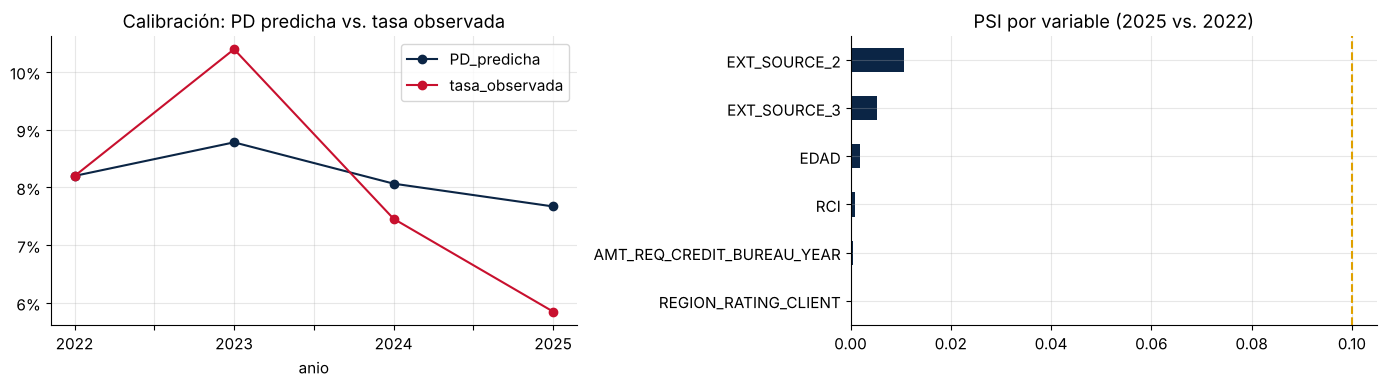

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
mon[["PD_predicha", "tasa_observada"]].plot(ax=ax[0], marker="o", color=[AZUL, ROJO]); ax[0].set_title("Calibración: PD predicha vs. tasa observada")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
# PSI por variable (CSI): ¿qué variable se movió?
csi = {}
for f in feats:
    b = np.unique(np.quantile(X.loc[dev, f], np.linspace(0, 1, 11))); b[0], b[-1] = -np.inf, np.inf
    csi[f] = psi(X.loc[dev, f], X.loc[app.anio == "2025", f], b)
pd.Series(csi).sort_values().plot(kind="barh", ax=ax[1], color=AZUL); ax[1].axvline(.1, color=ORO, ls="--"); ax[1].set_title("PSI por variable (2025 vs. 2022)")
plt.tight_layout(); plt.show()

**Lectura:** la población es estable (PSI bajo) y el modelo sigue ordenando (AUC estable), pero la **calibración** se desfasa con el ciclo: entrenado en 2022, el modelo **subestima** la PD en 2023 (pico de estrés) y la **sobreestima** en 2025 (entorno benigno). Es un caso típico: discriminación estable, calibración desfasada por el ciclo. La acción es **recalibrar**, no necesariamente redesarrollar. El monitoreo debe mirar las tres dimensiones a la vez.

## 3. Explicabilidad y supervisión humana
- **Explicabilidad:** cada decisión automática debe poder explicarse con **razones** (*reason codes*): las variables que más empujaron la PD del cliente hacia arriba respecto al promedio.
- **Supervisión humana:** revisión de casos límite, monitoreo de *overrides*, capacidad de detener el modelo y escalamiento. Esto es parte de los principios de IA responsable y de las guías supervisoras sobre gestión del riesgo de modelos.

In [5]:
coef = pd.Series(mod.coef_[0], index=feats)
medias = X[dev].mean()
def razones(i, k=3):
    contrib = coef * (X.loc[i] - medias)            # contribución al log-odds frente al cliente promedio
    return contrib.sort_values(ascending=False).head(k)
caso = app.loc[app.pd.idxmax()]
print(f"Cliente {caso.SK_ID_CURR}: PD = {caso.pd:.1%}. Principales razones:")
print(razones(app.pd.idxmax()).rename("aporte al log-odds").to_string())

Cliente 156562: PD = 68.7%. Principales razones:
RCI            1.3221
EXT_SOURCE_2   1.0401
EDAD           0.4479


> **Para discutir:** ¿qué razones son comunicables al cliente? ¿Cuáles no deberían usarse aunque predigan (variables protegidas o proxies)? Retomaremos explicabilidad con SHAP, PDP e ICE en el **Módulo 7**.

## 4. Champion–challenger: cambiar una política con evidencia
- **Champion:** corte de score de buró 415 (política vigente).
- **Challenger:** corte 365 con un tope de RCI de 100 %, aplicado a una muestra aleatoria de 20 %.

In [6]:
from statsmodels.stats.proportion import proportions_ztest
ext = app[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
app["SCORE"] = (ext.fillna(ext.median()) * 1000).round()
rng = np.random.default_rng(11)
app["grupo"] = np.where(rng.random(len(app)) < 0.2, "Challenger", "Champion")
app["aprobado"] = np.where(app.grupo == "Champion", app.SCORE >= 415, (app.SCORE >= 365) & (app.RCI <= 1.0))
cc = app.groupby("grupo").apply(lambda d: pd.Series({"solicitudes": len(d), "tasa_aprob": d.aprobado.mean(),
                                                     "tasa_malos": d.loc[d.aprobado, "TARGET"].mean()}))
display(cc.style.format({"solicitudes": "{:,.0f}", "tasa_aprob": "{:.1%}", "tasa_malos": "{:.2%}"}))
a = app[app.aprobado]
z, pval = proportions_ztest(a.groupby("grupo").TARGET.sum().values, a.groupby("grupo").TARGET.size().values)
print(f"Diferencia en tasa de malos: z = {z:.2f}, p-valor = {pval:.3f}")

,solicitudes,tasa_aprob,tasa_malos
grupo,,,
Challenger,"12,017",80.9%,5.34%
Champion,"48,043",77.6%,5.04%


Diferencia en tasa de malos: z = 1.18, p-valor = 0.237


**Gobierno del cambio:** hipótesis y métrica de éxito definidas antes, asignación aleatoria, tamaño de muestra con potencia suficiente (Módulo 2), maduración (30@3 / 60@6), decisión en comité con acta, despliegue gradual y plan de *rollback*.

## 5. Actividad integradora: diagnóstico del portafolio para el comité de riesgos
**Contexto:** eres el gerente de riesgos minoristas. El comité de la próxima semana debe decidir sobre una propuesta comercial de **crecer 20 % en consumo y tarjeta bajando el corte de admisión**. Prepara el diagnóstico.

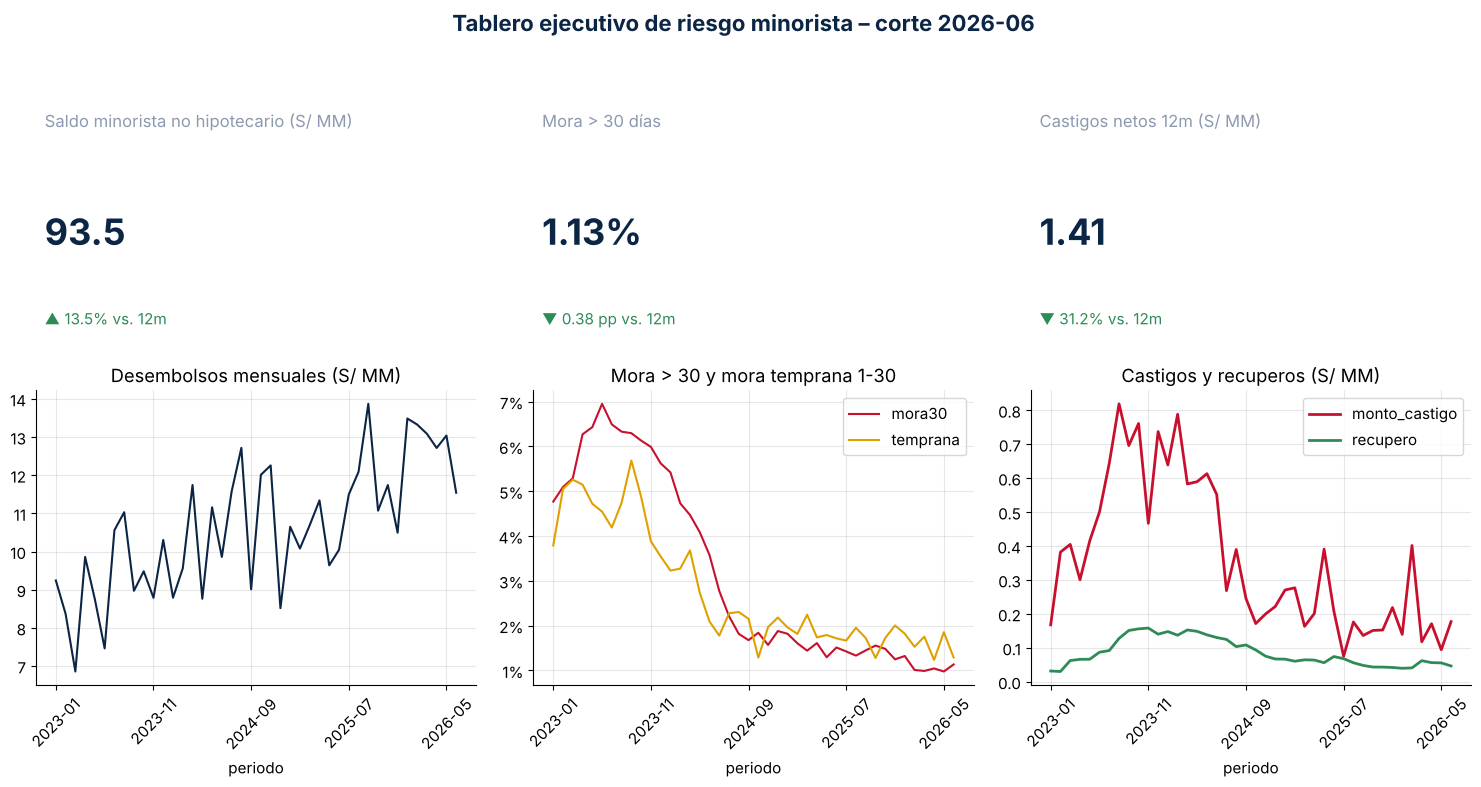

In [7]:
vig = p[p.estado == "Vigente"]
CORTE = "2026-06"
no_hip = vig[vig.producto != "Hipotecario"]
k = no_hip.groupby("periodo").apply(lambda d: pd.Series({"saldo": d.saldo.sum() / 1e6,
        "mora30": d.loc[d.dias_atraso > 30, "saldo"].sum() / d.saldo.sum(),
        "temprana": d.loc[d.dias_atraso.between(1, 30), "saldo"].sum() / d.saldo.sum()})).loc["2023-01":CORTE]
castm = p[p.producto != "Hipotecario"].groupby("periodo")[["monto_castigo", "recupero"]].sum().loc["2023-01":CORTE] / 1e6
desemb = p[p.mob == 1].groupby("periodo").monto_desembolsado.sum().loc["2023-01":CORTE] / 1e6
fig = plt.figure(figsize=(15, 8)); gs = fig.add_gridspec(2, 3)
def kpi(ax, titulo, valor, delta, bueno_si_baja=True, pp=False):
    ax.axis("off"); col = VERDE if (delta < 0) == bueno_si_baja else ROJO
    ax.text(0.02, 0.75, titulo, fontsize=12, color=GRIS); ax.text(0.02, 0.35, valor, fontsize=26, weight="bold", color=AZUL)
    ax.text(0.02, 0.08, f"{'▲' if delta > 0 else '▼'} " + (f"{abs(delta) * 100:.2f} pp" if pp else f"{abs(delta):.1%}") + " vs. 12m", fontsize=11, color=col)
kpi(fig.add_subplot(gs[0, 0]), "Saldo minorista no hipotecario (S/ MM)", f"{k.saldo.iloc[-1]:,.1f}", k.saldo.iloc[-1] / k.saldo.iloc[-13] - 1, bueno_si_baja=False)
kpi(fig.add_subplot(gs[0, 1]), "Mora > 30 días", f"{k.mora30.iloc[-1]:.2%}", k.mora30.iloc[-1] - k.mora30.iloc[-13], pp=True)
neto = castm.monto_castigo - castm.recupero
kpi(fig.add_subplot(gs[0, 2]), "Castigos netos 12m (S/ MM)", f"{neto.iloc[-12:].sum():,.2f}", neto.iloc[-12:].sum() / neto.iloc[-24:-12].sum() - 1)
ax1 = fig.add_subplot(gs[1, 0]); desemb.plot(ax=ax1, color=AZUL); ax1.set_title("Desembolsos mensuales (S/ MM)"); ax1.tick_params(axis="x", rotation=45)
ax2 = fig.add_subplot(gs[1, 1]); k[["mora30", "temprana"]].plot(ax=ax2, color=[ROJO, ORO]); ax2.set_title("Mora > 30 y mora temprana 1-30"); ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax2.tick_params(axis="x", rotation=45)
ax3 = fig.add_subplot(gs[1, 2]); castm.plot(ax=ax3, color=[ROJO, VERDE], lw=2); ax3.set_title("Castigos y recuperos (S/ MM)"); ax3.tick_params(axis="x", rotation=45)
fig.suptitle(f"Tablero ejecutivo de riesgo minorista – corte {CORTE}", fontsize=16, weight="bold", color=AZUL)
plt.tight_layout(); plt.show()

### Plantilla de memo para el comité (completar en grupos)

| Sección | Contenido esperado | Evidencia del laboratorio |
|---|---|---|
| 1. Situación | Crecimiento, mora (contable y ajustada), costo de riesgo, cobertura | Tablero; sesión 2 |
| 2. Señales adelantadas | Cosechas recientes, 30@3, roll rates, entradas a mora | Sesiones 2 y 3 |
| 3. Rentabilidad | RAROC por producto frente al costo de capital | Sesión 2, sección 7 |
| 4. Evaluación de la propuesta | Efecto del nuevo corte (champion–challenger), plan de crecimiento, EL y capital | Sesión 3 y sección 4 |
| 5. Riesgos y controles | Concentración, capacidad de cobranza, calidad de datos, calibración del modelo | Secciones 1-3 |
| 6. Recomendación | Aprobar, aprobar con condiciones (canal, límites, monitoreo, rollback) o rechazar | Síntesis |

**Criterios de evaluación:** uso de evidencia cuantitativa, reconocimiento de supuestos y limitaciones, y claridad de la recomendación.

### Tendencias en decisiones crediticias (para la discusión final)
- **Automatización de punta a punta:** motores de decisión, originación digital en minutos, aprobación instantánea.
- **Analítica avanzada e IA:** gradient boosting (Módulos 4-5), datos alternativos (transaccionales, open banking, pagos digitales), modelos de lenguaje para documentos y cobranza.
- **Canales digitales:** billeteras, embedded finance, BNPL; nuevos riesgos de fraude y de sobreendeudamiento.
- **Regulación y responsabilidad:** gestión del riesgo de modelos, explicabilidad, sesgo y supervisión humana.

## 6. Ejercicios
1. Agrega al reporte de calidad un control de **outliers** (ingreso > percentil 99,9). ¿Cuántos casos?
2. Recalibra el modelo de 2022 con los datos de 2024 (ajuste del intercepto). ¿Cuánto mejora la calibración de 2025?
3. Redacta en 5 líneas la recomendación al comité.